<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_095_rnn_real_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 95/365 — Practical RNN on a Real Dataset

Today we move from CNNs to sequence models.

Goal:

**Use a Recurrent Neural Network (RNN) to predict future sunspot activity from previous years.**

Dataset:

`statsmodels.datasets.sunspots`

This is a real historical sunspot activity dataset included with statsmodels.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error

from statsmodels.datasets import sunspots


## 1. Load the real dataset

In [2]:
data = sunspots.load_pandas().data.copy()

data.head()


,YEAR,SUNACTIVITY
0,1700.0,5.0
1,1701.0,11.0
2,1702.0,16.0
3,1703.0,23.0
4,1704.0,36.0


In [3]:
print("Rows:", len(data))
print(data.columns)


Rows: 309
Index(['YEAR', 'SUNACTIVITY'], dtype='object')


The important columns are:

- `YEAR`
- `SUNACTIVITY`

We want the model to learn:

**previous years → next year's sunspot activity**


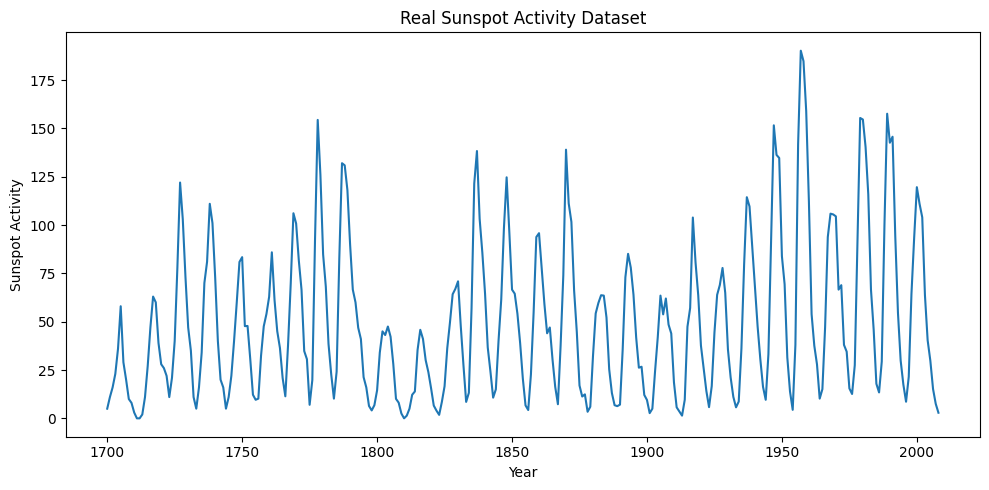

In [4]:
years = data["YEAR"].astype(int).values

values = (
    data["SUNACTIVITY"]
    .astype(np.float32)
    .values
    .reshape(-1,1)
)

plt.figure(figsize=(10,5))
plt.plot(years, values.ravel())
plt.xlabel("Year")
plt.ylabel("Sunspot Activity")
plt.title("Real Sunspot Activity Dataset")
plt.tight_layout()
plt.show()


## 2. Chronological split

Use the first 80% for training and the latest 20% for testing.

Do not randomly shuffle time-series data before splitting.


In [5]:
split_idx = int(len(values) * 0.8)

train_values = values[:split_idx]
test_values = values[split_idx:]

print("Train:", len(train_values))
print("Test:", len(test_values))


Train: 247
Test: 62


## 3. Scale using training data only

In [6]:
scaler = MinMaxScaler()

scaler.fit(train_values)

values_scaled = scaler.transform(values)


## 4. Build sequences

Use the previous 12 years to predict the next year:

`[t-12, ..., t-1] → t`


In [7]:
sequence_length = 12

X, y = [], []

for i in range(len(values_scaled) - sequence_length):
    X.append(
        values_scaled[i:i+sequence_length]
    )
    y.append(
        values_scaled[i+sequence_length]
    )

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

print("X:", X.shape)
print("y:", y.shape)


X: (297, 12, 1)
y: (297, 1)


## 5. Keep train/test boundaries chronological

In [8]:
target_indices = np.arange(
    sequence_length,
    len(values_scaled)
)

train_mask = target_indices < split_idx
test_mask = target_indices >= split_idx

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("Train sequences:", X_train.shape)
print("Test sequences:", X_test.shape)


Train sequences: (235, 12, 1)
Test sequences: (62, 12, 1)


## 6. Create mini-batches

In [9]:
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train),
        torch.tensor(y_train)
    ),
    batch_size=32,
    shuffle=True
)


## 7. Build a simple RNN

The RNN reads each value in the 12-year sequence one after another.

Its hidden state carries information forward through the sequence.


In [10]:
class SimpleRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=24,
            batch_first=True
        )

        self.fc = nn.Linear(
            24,
            1
        )

    def forward(self, x):

        output, hidden = self.rnn(x)

        last_step = output[:, -1, :]

        return self.fc(last_step)


In [11]:
torch.manual_seed(42)

model = SimpleRNN()

print(model)


SimpleRNN(
  (rnn): RNN(1, 24, batch_first=True)
  (fc): Linear(in_features=24, out_features=1, bias=True)
)


## 8. Loss and optimizer

This is a regression problem.

Use:

- MSE Loss
- Adam


In [12]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)


## 9. Train the model

In [13]:
epochs = 150
losses = []

for epoch in range(epochs):

    model.train()

    total_loss = 0
    total_samples = 0

    for xb, yb in train_loader:

        optimizer.zero_grad()

        prediction = model(xb)

        loss = criterion(
            prediction,
            yb
        )

        loss.backward()

        optimizer.step()

        total_loss += (
            loss.item() * xb.size(0)
        )

        total_samples += xb.size(0)

    epoch_loss = (
        total_loss / total_samples
    )

    losses.append(epoch_loss)

print("Final loss:", losses[-1])


Final loss: 0.004447170765079716


## 10. Plot training loss

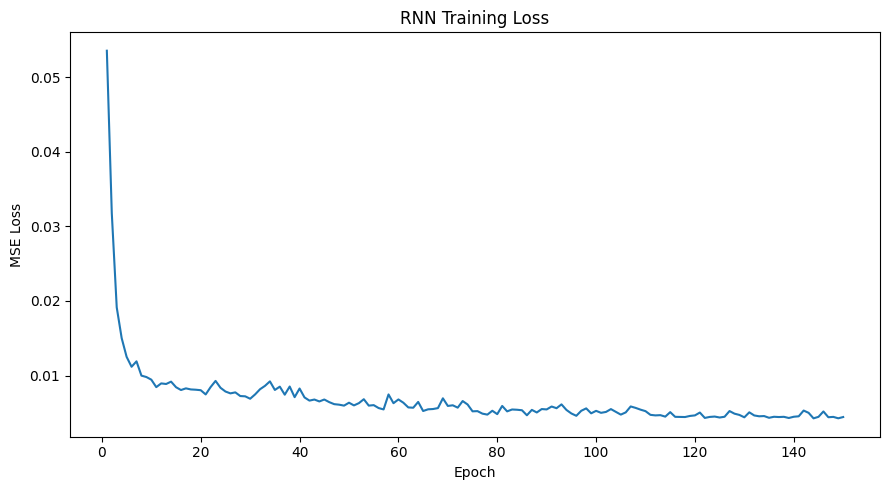

In [14]:
plt.figure(figsize=(9,5))

plt.plot(
    range(1, epochs+1),
    losses
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("RNN Training Loss")
plt.tight_layout()
plt.show()


## 11. Predict the unseen period

In [15]:
model.eval()

with torch.no_grad():

    pred_scaled = model(
        torch.tensor(X_test)
    ).numpy()

pred = scaler.inverse_transform(
    pred_scaled
)

actual = scaler.inverse_transform(
    y_test
)

test_years = years[
    target_indices[test_mask]
]

mae = mean_absolute_error(
    actual.ravel(),
    pred.ravel()
)

print("Test MAE:", round(mae,2))


Test MAE: 13.84


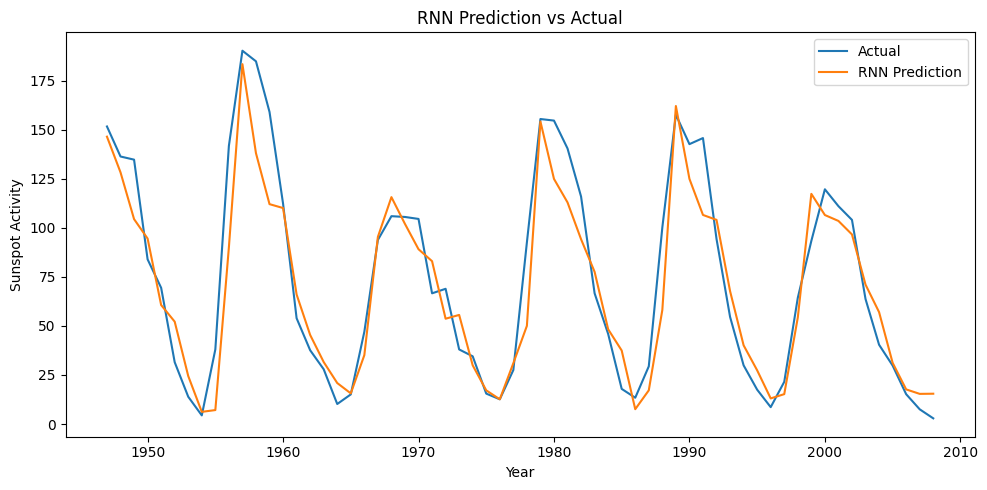

In [16]:
plt.figure(figsize=(10,5))

plt.plot(
    test_years,
    actual.ravel(),
    label="Actual"
)

plt.plot(
    test_years,
    pred.ravel(),
    label="RNN Prediction"
)

plt.xlabel("Year")
plt.ylabel("Sunspot Activity")
plt.title("RNN Prediction vs Actual")
plt.legend()
plt.tight_layout()
plt.show()


## 12. What makes an RNN different?

A normal feed-forward network treats inputs independently.

An RNN keeps a **hidden state**.

Conceptually:

`x1 → h1`

`x2 + h1 → h2`

`x3 + h2 → h3`

So earlier sequence information can influence later predictions.


## 13. Limitation of basic RNNs

Basic RNNs struggle with long-term dependencies because gradients can vanish or explode over many time steps.

That is why:

- LSTM
- GRU

were developed.


## Simple takeaway

CNNs are built around **spatial structure**.

RNNs are built around **sequential structure**.

> **An RNN carries information from previous steps through its hidden state and uses that memory to process what comes next.**


## References

- statsmodels Sunspots:
  https://www.statsmodels.org/stable/datasets/generated/sunspots.html

- PyTorch RNN:
  https://pytorch.org/docs/stable/generated/torch.nn.RNN.html

- Understanding LSTM Networks:
  https://colah.github.io/posts/2015-08-Understanding-LSTMs/
